# NB1 - EuroSAT-MS data preparation (GeoGraphNet)

**Run on:** CPU (accelerator: None). **Input to add:** your uploaded official EuroSAT-MS (13-band GeoTIFF) dataset.
Click *Run All*. Total run time depends on disk speed; the slowest cell is the 13-band load (Cell 3).

**Outputs (in /kaggle/working):** `folds.csv`, `X13_uint16.npy`, `labels.npy`, `X16_float16.npy`,
`channel_stats.json`, `near_duplicates.csv`, `eda_band_means.png`, `data_root.txt`.
After the run: *Save Version*, then create a Kaggle Dataset from the output for NB2 and NB3.


**Band storage order (verified in Cell 4): B1..B8, B9, B10, B11, B12, B8A.** NDBI uses B11 = index 10.


## Cell 1 - Find and verify the dataset

In [1]:
import os, re, glob, zipfile, random, subprocess, sys
from collections import Counter
import numpy as np, pandas as pd
try:
    import rasterio
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "rasterio"], check=True)
    import rasterio

os.makedirs("/kaggle/working", exist_ok=True)
random.seed(42); np.random.seed(42)
ROOT = "/kaggle/input"
OFFICIAL = {"AnnualCrop": 3000, "Forest": 3000, "HerbaceousVegetation": 3000, "Highway": 2500,
            "Industrial": 2500, "Pasture": 2000, "PermanentCrop": 2500, "Residential": 3000,
            "River": 2500, "SeaLake": 3000}

# what is mounted (top levels)
for dp, dn, fn in os.walk(ROOT):
    depth = dp[len(ROOT):].count(os.sep)
    if depth <= 4:
        print("  " * depth + (os.path.basename(dp) or dp) + f"/  [{len(dn)} folders, {len(fn)} files]")
    if depth >= 4:
        dn[:] = []

# extract zips only if the data was not auto-extracted
tifs = glob.glob(f"{ROOT}/**/*.tif", recursive=True) + glob.glob(f"{ROOT}/**/*.tiff", recursive=True)
zips = glob.glob(f"{ROOT}/**/*.zip", recursive=True)
if not tifs and zips:
    out = "/kaggle/working/eurosat_ms"
    for z in zips:
        print("extracting", z)
        zipfile.ZipFile(z).extractall(out)
    tifs = glob.glob(f"{out}/**/*.tif", recursive=True)
assert tifs, "No .tif files found: add the EuroSAT-MS dataset under Input"

parents = sorted({os.path.dirname(f) for f in tifs})
data_root = sorted({os.path.dirname(p) for p in parents})
print("\nclass-folder parent(s):", data_root)
assert len(data_root) == 1, "more than one data root: check the printed tree"
DATA_ROOT = data_root[0]
open("/kaggle/working/data_root.txt", "w").write(DATA_ROOT)

rows, bad = [], []
for c in sorted(os.listdir(DATA_ROOT)):
    p = f"{DATA_ROOT}/{c}"
    if not os.path.isdir(p):
        continue
    fs = os.listdir(p)
    ok = [f for f in fs if re.match(rf"^{c}_\d+\.tif$", f)]
    bad += [f"{c}/{f}" for f in fs if f not in ok]
    rows.append((c, len(fs), len(ok), OFFICIAL.get(c)))
df = pd.DataFrame(rows, columns=["class", "files", "official_name_pattern", "official_count"])
print("\n", df.to_string(index=False))
assert bool((df["files"] == df["official_count"]).all()) and not bad, "counts/names differ from the official release"
print("\nOK: 27,000 files, official counts and names")

for f in random.sample(tifs, 3):
    with rasterio.open(f) as s:
        print(f"{os.path.relpath(f, DATA_ROOT)}  bands={s.count}  size={s.width}x{s.height}  dtype={s.dtypes[0]}")
print("DATA_ROOT =", DATA_ROOT)

input/  [1 folders, 0 files]
  datasets/  [1 folders, 0 files]
    sudeeptamandal/  [1 folders, 0 files]
      eurosat-ms/  [1 folders, 0 files]
        EuroSAT_MS/  [10 folders, 0 files]

class-folder parent(s): ['/kaggle/input/datasets/sudeeptamandal/eurosat-ms/EuroSAT_MS']

                class  files  official_name_pattern  official_count
          AnnualCrop   3000                   3000            3000
              Forest   3000                   3000            3000
HerbaceousVegetation   3000                   3000            3000
             Highway   2500                   2500            2500
          Industrial   2500                   2500            2500
             Pasture   2000                   2000            2000
       PermanentCrop   2500                   2500            2500
         Residential   3000                   3000            3000
               River   2500                   2500            2500
             SeaLake   3000                   3000 

## Cell 2 - Index, stratified 5-fold, Phase 1 split

In [2]:
import os, pandas as pd, numpy as np
from sklearn.model_selection import StratifiedKFold

DATA_ROOT = open("/kaggle/working/data_root.txt").read().strip()
classes = sorted(d for d in os.listdir(DATA_ROOT) if os.path.isdir(f"{DATA_ROOT}/{d}"))
cls2id = {c: i for i, c in enumerate(classes)}

rows = [(f"{c}/{f}", c, cls2id[c]) for c in classes
        for f in sorted(os.listdir(f"{DATA_ROOT}/{c}")) if f.endswith(".tif")]
idx = pd.DataFrame(rows, columns=["rel", "class", "label"])
assert len(idx) == 27000 and idx["rel"].is_unique

# 5-fold stratified (Phase 2: final cross-validation)
idx["fold"] = -1
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for k, (_, te) in enumerate(skf.split(idx["rel"], idx["label"])):
    idx.loc[idx.index[te], "fold"] = k
assert (idx["fold"] >= 0).all()

# Phase 1 (development): test = fold 0, val = fold 1, train = folds 2-4
idx["phase1"] = idx["fold"].map({0: "test", 1: "val", 2: "train", 3: "train", 4: "train"})
idx.to_csv("/kaggle/working/folds.csv", index=False)

print(pd.crosstab(idx["class"], idx["fold"]))
print("\nclass ids:", cls2id)
print("Phase 1:", idx["phase1"].value_counts().to_dict())

fold                    0    1    2    3    4
class                                        
AnnualCrop            600  600  600  600  600
Forest                600  600  600  600  600
HerbaceousVegetation  600  600  600  600  600
Highway               500  500  500  500  500
Industrial            500  500  500  500  500
Pasture               400  400  400  400  400
PermanentCrop         500  500  500  500  500
Residential           600  600  600  600  600
River                 500  500  500  500  500
SeaLake               600  600  600  600  600

class ids: {'AnnualCrop': 0, 'Forest': 1, 'HerbaceousVegetation': 2, 'Highway': 3, 'Industrial': 4, 'Pasture': 5, 'PermanentCrop': 6, 'Residential': 7, 'River': 8, 'SeaLake': 9}
Phase 1: {'train': 16200, 'val': 5400, 'test': 5400}


## Cell 3 - Load all 13-band patches (slowest cell) and save

In [3]:
import time, os, numpy as np, pandas as pd
import tifffile
from tqdm.auto import tqdm

DATA_ROOT = open("/kaggle/working/data_root.txt").read().strip()
idx = pd.read_csv("/kaggle/working/folds.csv")
N = len(idx); assert N == 27000
P13 = "/kaggle/working/X13_uint16.npy"

if os.path.exists(P13):
    X13 = np.load(P13)
    print("loaded cached", P13)
else:
    def read(rel):
        a = tifffile.imread(f"{DATA_ROOT}/{rel}")
        # tifffile (64, 64, 13) শেপে রিড করলে সেটিকে rasterio-এর মতো (13, 64, 64) করে নেয়
        return a.transpose(2, 0, 1) if a.shape == (64, 64, 13) else a

    t0 = time.time()
    X13 = np.zeros((N, 13, 64, 64), dtype=np.uint16)
    for i, rel in enumerate(tqdm(idx["rel"], total=N, desc="loading")):
        a = read(rel)
        assert a.shape == (13, 64, 64)
        X13[i] = a
    print(f"loaded in {(time.time()-t0)/60:.1f} min")
    np.save(P13, X13)

y = idx["label"].values.astype(np.int64)
np.save("/kaggle/working/labels.npy", y)
print(X13.shape, X13.dtype, "min", X13.min(), "max", X13.max())

loading:   0%|          | 0/27000 [00:00<?, ?it/s]

loaded in 13.4 min
(27000, 13, 64, 64) uint16 min 0 max 28003


## Cell 4 - Verify band order and value range, look at samples

fraction of values > 10000: 1.730407540954416e-05


,B1,B2,B3,B4,B5,B6,B7,B8,B9,B10,B11,B12,B8A
AnnualCrop,0.142,0.126,0.129,0.140,0.169,0.266,0.319,0.309,0.085,0.001,0.266,0.169,0.353
Forest,0.111,0.081,0.069,0.042,0.075,0.210,0.269,0.264,0.082,0.001,0.131,0.054,0.301
HerbaceousVegetation,0.132,0.111,0.106,0.105,0.137,0.206,0.236,0.237,0.105,0.002,0.235,0.144,0.265
Highway,0.135,0.111,0.104,0.095,0.123,0.217,0.259,0.251,0.079,0.001,0.196,0.120,0.284
Industrial,0.167,0.147,0.137,0.137,0.151,0.200,0.224,0.212,0.063,0.001,0.206,0.150,0.238
Pasture,0.130,0.101,0.095,0.066,0.118,0.280,0.345,0.339,0.111,0.001,0.197,0.095,0.384
PermanentCrop,0.141,0.122,0.125,0.132,0.160,0.246,0.287,0.278,0.081,0.001,0.269,0.176,0.316
Residential,0.146,0.121,0.111,0.108,0.129,0.198,0.229,0.219,0.067,0.001,0.197,0.138,0.247
River,0.130,0.104,0.093,0.072,0.093,0.172,0.207,0.199,0.060,0.001,0.131,0.072,0.225
SeaLake,0.123,0.095,0.078,0.051,0.051,0.040,0.040,0.033,0.010,0.001,0.010,0.006,0.032


Forest: B8 > B4  : True
SeaLake: B8 < B3 : True
max B10 across classes (should be small): 0.0016
B10 (cirrus) < 0.01: True | B8A close to B8: True | SeaLake B8A < 0.05: True


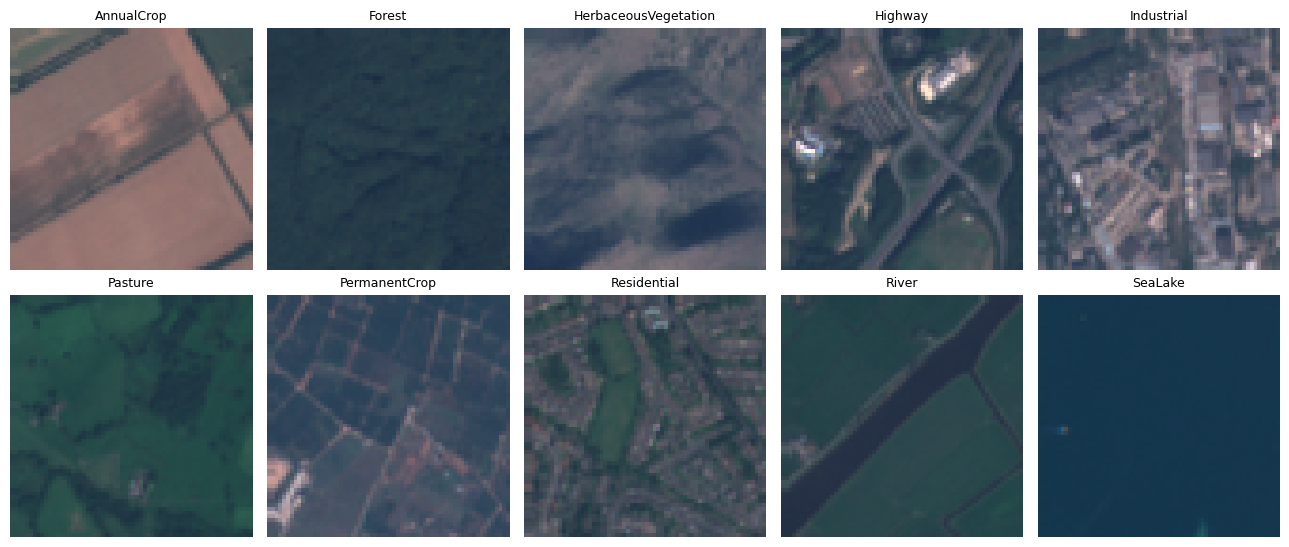

In [4]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

idx = pd.read_csv("/kaggle/working/folds.csv")
cls = idx["class"].values
BANDS = ["B1","B2","B3","B4","B5","B6","B7","B8","B9","B10","B11","B12","B8A"]   # verified storage order

print("fraction of values > 10000:", float((X13 > 10000).mean()))
means = {c: X13[cls == c].mean(axis=(0, 2, 3), dtype=np.float32) / 10000.0 for c in sorted(set(cls))}
m = pd.DataFrame(means, index=BANDS).T
display(m.round(3))
chk1 = bool(m.loc["Forest", "B8"] > m.loc["Forest", "B4"])
chk2 = bool(m.loc["SeaLake", "B8"] < m.loc["SeaLake", "B3"])
print("Forest: B8 > B4  :", chk1)
print("SeaLake: B8 < B3 :", chk2)
print("max B10 across classes (should be small):", round(float(m["B10"].max()), 4))
chk3 = bool(m["B10"].max() < 0.01)                                   # cirrus is ~0
chk4 = bool((m["B8A"] - m["B8"]).abs().max() < 0.1)                    # B8A tracks B8 per class
chk5 = bool(m.loc["SeaLake", "B8A"] < 0.05)
print("B10 (cirrus) < 0.01:", chk3, "| B8A close to B8:", chk4, "| SeaLake B8A < 0.05:", chk5)
assert chk1 and chk2 and chk3 and chk4 and chk5, "band order looks wrong: stop and check the dataset"

# one sample per class, B4,B3,B2 as R,G,B
rng = np.random.default_rng(0)
fig, ax = plt.subplots(2, 5, figsize=(13, 5.6))
for a, c in zip(ax.ravel(), sorted(set(cls))):
    i = rng.choice(np.where(cls == c)[0])
    rgb = np.clip((X13[i, [3, 2, 1]].astype(np.float32) / 10000.0) / 0.3, 0, 1).transpose(1, 2, 0)
    a.imshow(rgb); a.set_title(c, fontsize=9); a.axis("off")
plt.tight_layout(); plt.show()

## Cell 5 - 16-channel tensor (13 bands + NDVI, NDWI, NDBI) and normalisation statistics

Channels 0-12 are the scaled bands in storage order (B1..B8, B9, B10, B11, B12, B8A), channel 13 = NDVI, 14 = NDWI, 15 = NDBI.
Mean/std are computed on training folds only (per CV fold, and for the Phase 1 train folds 2-4).

In [5]:
import json, numpy as np, pandas as pd

idx = pd.read_csv("/kaggle/working/folds.csv")
fold = idx["fold"].values
N = len(idx)
EPS = 1e-6

def make16(x13):                                    # (n,13,64,64) uint16 -> (n,16,64,64) float32
    x = np.clip(x13.astype(np.float32) / 10000.0, 0, 1)
    B3, B4, B8, B11 = x[:, 2], x[:, 3], x[:, 7], x[:, 10]   # B11 = index 10 (storage order ...B9,B10,B11,B12,B8A)
    ndvi = (B8 - B4) / (B8 + B4 + EPS)
    ndwi = (B3 - B8) / (B3 + B8 + EPS)
    ndbi = (B11 - B8) / (B11 + B8 + EPS)
    return np.concatenate([x, ndvi[:, None], ndwi[:, None], ndbi[:, None]], 1)

X16 = np.empty((N, 16, 64, 64), dtype=np.float16)
S = np.zeros((5, 16)); Q = np.zeros((5, 16)); n = np.zeros(5)
for s in range(0, N, 1000):
    c = make16(X13[s:s + 1000])
    X16[s:s + 1000] = c.astype(np.float16)
    c64, f = c.astype(np.float64), fold[s:s + 1000]
    for k in range(5):
        sel = c64[f == k]
        if len(sel):
            S[k] += sel.sum((0, 2, 3)); Q[k] += (sel ** 2).sum((0, 2, 3)); n[k] += len(sel) * 64 * 64

print("X16:", X16.shape, X16.dtype, "| NaN:", int(np.isnan(X16).sum()), "| Inf:", int(np.isinf(X16).sum()))

def stats(folds):
    ss, qq, nn = S[folds].sum(0), Q[folds].sum(0), n[folds].sum()
    mu = ss / nn
    sd = np.sqrt(np.maximum(qq / nn - mu ** 2, 1e-12))
    return {"mean": mu.tolist(), "std": sd.tolist()}

out = {"channels": ["B1","B2","B3","B4","B5","B6","B7","B8","B9","B10","B11","B12","B8A","NDVI","NDWI","NDBI"],
       "phase1_train_folds_2_3_4": stats([2, 3, 4]),
       "cv_train_excluding_fold": {str(k): stats([j for j in range(5) if j != k]) for k in range(5)}}
json.dump(out, open("/kaggle/working/channel_stats.json", "w"))
np.save("/kaggle/working/X16_float16.npy", X16)

st = pd.DataFrame({"mean": out["phase1_train_folds_2_3_4"]["mean"], "std": out["phase1_train_folds_2_3_4"]["std"]},
                  index=out["channels"])
display(st.round(4))
print("saved X16_float16.npy and channel_stats.json")

X16: (27000, 16, 64, 64) float16 | NaN: 0 | Inf: 0


,mean,std
B1,0.1354,0.0246
B2,0.1118,0.0332
B3,0.1043,0.0393
B4,0.0947,0.0591
B5,0.1199,0.0564
B6,0.2001,0.0858
B7,0.2372,0.1085
B8,0.2299,0.1116
B9,0.0730,0.0403
B10,0.0012,0.0005


saved X16_float16.npy and channel_stats.json


## Cell 6 - Near-duplicate check across folds (leakage)

For every patch, the most similar patch in a *different* fold is found (cosine similarity of mean-centred 16x16 thumbnails of B8, B4, B3,
which equals the Pearson correlation). High values are candidates only; look at the pairs before deciding to remove anything.

similarity to nearest patch in another fold, percentiles 50/90/99/99.9: [0.93  0.992 1.    1.   ]
patches with similarity > 0.98: 5528
patches with similarity > 0.99: 3239
patches with similarity > 0.995: 2178
saved near_duplicates.csv with 5528 rows (threshold 0.98)
{'SeaLake': 2252, 'Forest': 1866, 'HerbaceousVegetation': 582, 'Pasture': 528, 'PermanentCrop': 149, 'AnnualCrop': 123, 'Highway': 18, 'Residential': 6, 'River': 4}


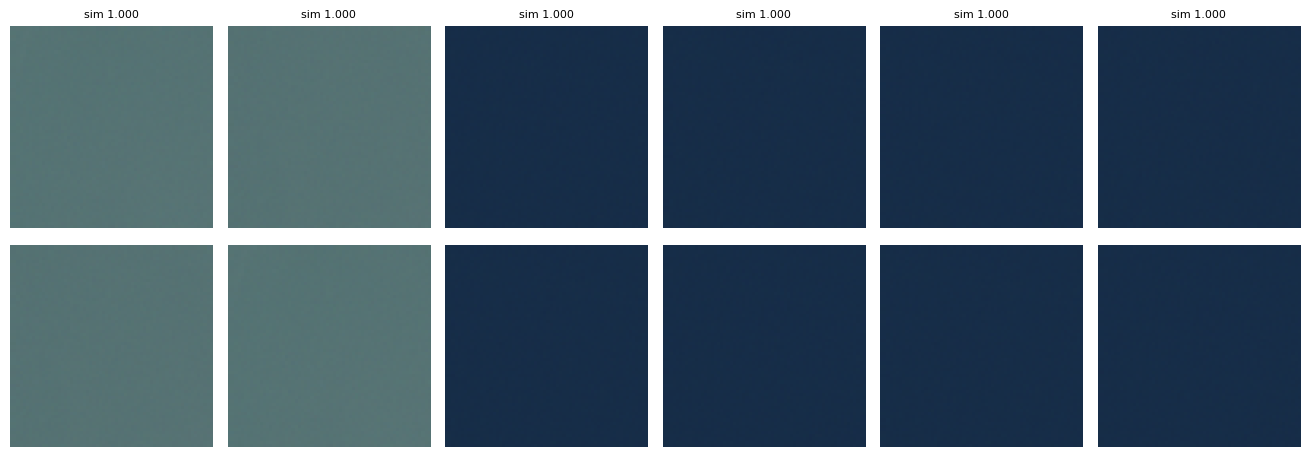

In [6]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

idx = pd.read_csv("/kaggle/working/folds.csv")
fold = idx["fold"].values
N = len(idx)

th = X13[:, [7, 3, 2]].astype(np.float32) / 10000.0                    # B8, B4, B3
th = th.reshape(N, 3, 16, 4, 16, 4).mean((3, 5)).reshape(N, -1)
th -= th.mean(1, keepdims=True)
th /= (np.linalg.norm(th, axis=1, keepdims=True) + 1e-8)

best = np.zeros(N, np.float32); bestj = np.zeros(N, np.int64)
for s in range(0, N, 500):
    sim = th[s:s + 500] @ th.T
    sim[fold[s:s + 500, None] == fold[None, :]] = -1.0                   # ignore same-fold (and self)
    best[s:s + 500] = sim.max(1); bestj[s:s + 500] = sim.argmax(1)

print("similarity to nearest patch in another fold, percentiles 50/90/99/99.9:",
      np.percentile(best, [50, 90, 99, 99.9]).round(3))
for thr in (0.98, 0.99, 0.995):
    print(f"patches with similarity > {thr}: {(best > thr).sum()}")

pairs = pd.DataFrame({"i": np.arange(N), "j": bestj, "sim": best,
                      "rel_i": idx["rel"].values, "rel_j": idx["rel"].values[bestj],
                      "fold_i": fold, "fold_j": fold[bestj]})
pairs = pairs[pairs["sim"] > 0.98].sort_values("sim", ascending=False)
pairs.to_csv("/kaggle/working/near_duplicates.csv", index=False)
print("saved near_duplicates.csv with", len(pairs), "rows (threshold 0.98)")
print(pairs.assign(c_i=idx["class"].values[pairs["i"]])["c_i"].value_counts().to_dict() if len(pairs) else "no candidates")

top = pairs.head(6)
if len(top):
    fig, ax = plt.subplots(2, len(top), figsize=(2.2 * len(top), 4.8), squeeze=False)
    for col, (_, r) in enumerate(top.iterrows()):
        for row, key in enumerate(("i", "j")):
            rgb = np.clip((X13[int(r[key]), [3, 2, 1]].astype(np.float32) / 10000.0) / 0.3, 0, 1).transpose(1, 2, 0)
            ax[row, col].imshow(rgb); ax[row, col].axis("off")
        ax[0, col].set_title(f"sim {r['sim']:.3f}", fontsize=8)
    plt.tight_layout(); plt.show()

## Cell 7 - EDA (class band profiles, indices) and output summary

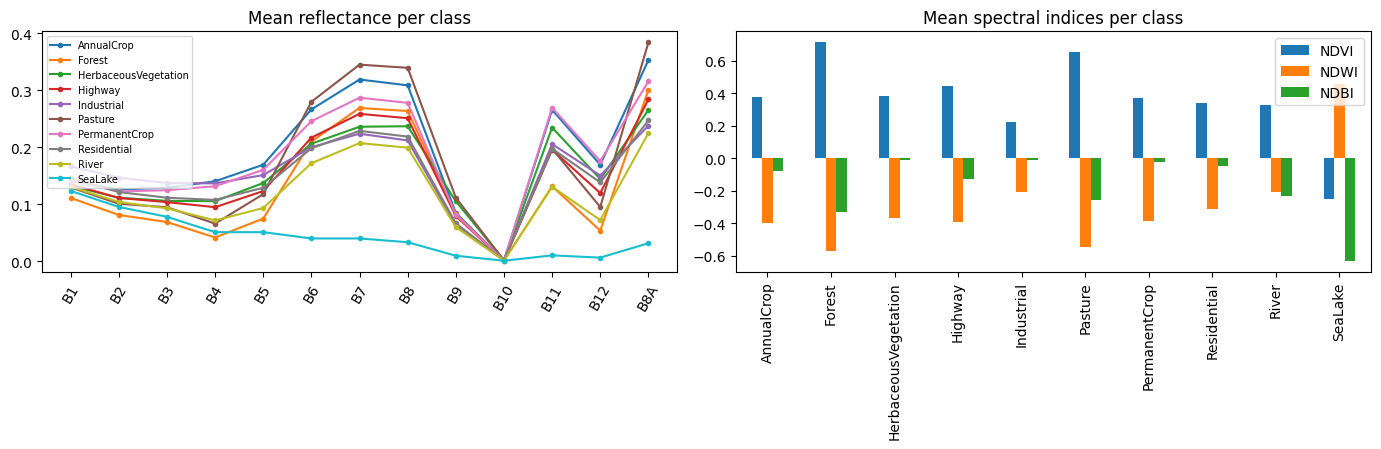

,NDVI,NDWI,NDBI
AnnualCrop,0.376,-0.396,-0.079
Forest,0.713,-0.569,-0.332
HerbaceousVegetation,0.385,-0.370,-0.012
Highway,0.446,-0.392,-0.125
Industrial,0.223,-0.204,-0.008
Pasture,0.654,-0.544,-0.254
PermanentCrop,0.372,-0.383,-0.022
Residential,0.340,-0.311,-0.046
River,0.327,-0.209,-0.230
SeaLake,-0.253,0.456,-0.630



class counts: {'AnnualCrop': 3000, 'Forest': 3000, 'HerbaceousVegetation': 3000, 'Highway': 2500, 'Industrial': 2500, 'Pasture': 2000, 'PermanentCrop': 2500, 'Residential': 3000, 'River': 2500, 'SeaLake': 3000}

files in /kaggle/working:
  X13_uint16.npy                  2875.4 MB
  X16_float16.npy                 3538.9 MB
  __notebook__.ipynb                 0.3 MB
  channel_stats.json                 0.0 MB
  data_root.txt                      0.0 MB
  eda_band_means.png                 0.2 MB
  folds.csv                          1.4 MB
  labels.npy                         0.2 MB
  near_duplicates.csv                0.4 MB

Next: Save Version, then create a Kaggle Dataset from this notebook's output (for NB2 and NB3).


In [7]:
import os, numpy as np, pandas as pd
import matplotlib.pyplot as plt

idx = pd.read_csv("/kaggle/working/folds.csv")
cls = idx["class"].values
names = sorted(set(cls))
BANDS = ["B1","B2","B3","B4","B5","B6","B7","B8","B9","B10","B11","B12","B8A"]   # verified storage order

# per-class mean spectral profile
prof = {c: X16[cls == c][:, :13].mean(axis=(0, 2, 3), dtype=np.float32) for c in names}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for c in names:
    ax[0].plot(BANDS, prof[c], marker="o", ms=3, label=c)
ax[0].set_title("Mean reflectance per class"); ax[0].tick_params(axis="x", rotation=60); ax[0].legend(fontsize=7)

# per-class mean indices
ind = pd.DataFrame({c: X16[cls == c][:, 13:].mean(axis=(0, 2, 3), dtype=np.float32) for c in names},
                   index=["NDVI", "NDWI", "NDBI"]).T
ind.plot(kind="bar", ax=ax[1]); ax[1].set_title("Mean spectral indices per class")
plt.tight_layout(); plt.savefig("/kaggle/working/eda_band_means.png", dpi=130); plt.show()
display(ind.round(3))

print("\nclass counts:", idx["class"].value_counts().sort_index().to_dict())
print("\nfiles in /kaggle/working:")
for f in sorted(os.listdir("/kaggle/working")):
    p = os.path.join("/kaggle/working", f)
    if os.path.isfile(p):
        print(f"  {f:28s} {os.path.getsize(p)/1e6:9.1f} MB")
print("\nNext: Save Version, then create a Kaggle Dataset from this notebook's output (for NB2 and NB3).")

In [8]:
import hashlib, numpy as np, pandas as pd

idx = pd.read_csv("/kaggle/working/folds.csv")
try:
    X13
except NameError:
    X13 = np.load("/kaggle/working/X13_uint16.npy", mmap_mode="r")
try:
    X16
except NameError:
    X16 = np.load("/kaggle/working/X16_float16.npy", mmap_mode="r")
N = len(idx)
CH = ["B1","B2","B3","B4","B5","B6","B7","B8","B9","B10","B11","B12","B8A","NDVI","NDWI","NDBI"]

# 1) overview: rows / columns / size
print(f"patches (rows)        : {N:,}")
print(f"channels (columns)    : 13 raw bands + 3 indices = {X16.shape[1]}")
print(f"patch size            : {X13.shape[2]} x {X13.shape[3]} = {X13.shape[2]*X13.shape[3]:,} pixels per channel")
print(f"values per patch      : {int(np.prod(X13.shape[1:])):,} (13 x 64 x 64)")
print(f"dtype X13 / X16       : {X13.dtype} / {X16.dtype}")
print(f"memory X13 / X16 (GB) : {X13.nbytes/1e9:.2f} / {X16.nbytes/1e9:.2f}")

# 2) class distribution and per-fold balance
cd = idx["class"].value_counts().sort_index().to_frame("count")
cd["percent"] = (cd["count"] / N * 100).round(2)
cd = cd.join(pd.crosstab(idx["class"], idx["fold"]).add_prefix("fold"))
display(cd)

# 3) per-channel summary statistics (1,000 random patches)
rng = np.random.default_rng(0)
sel = np.sort(rng.choice(N, min(1000, N), replace=False))
sub = np.asarray(X16[sel], dtype=np.float32).transpose(1, 0, 2, 3).reshape(16, -1)
p = np.percentile(sub, [1, 50, 99], axis=1)
summ = pd.DataFrame({"min": sub.min(1), "p1": p[0], "median": p[1], "p99": p[2], "max": sub.max(1),
                     "mean": sub.mean(1), "std": sub.std(1)}, index=CH)
display(summ.round(4))

# 4) data quality (whole dataset, in chunks)
nan = inf = 0; allzero = 0; const_band = np.zeros(13, int); n0 = n_max = tot = 0
for s in range(0, N, 1000):
    a16 = np.asarray(X16[s:s+1000]); nan += int(np.isnan(a16).sum()); inf += int(np.isinf(a16).sum())
    a = np.asarray(X13[s:s+1000]); n = len(a)
    allzero += int((a.reshape(n, -1).max(1) == 0).sum())
    const_band += (a.reshape(n, 13, -1).std(2) == 0).sum(0)
    n0 += int((a == 0).sum()); n_max += int((a == 65535).sum()); tot += a.size
print(f"\nNaN / Inf in X16        : {nan} / {inf}")
print(f"all-zero patches        : {allzero}")
print(f"patches with a constant band, per band: {dict(zip(CH[:13], const_band.tolist()))}")
print(f"fraction of raw values == 0: {n0/tot:.5f} | == 65535: {n_max/tot:.5f}")

# 5) exact duplicates (identical pixel data)
h = [hashlib.md5(np.ascontiguousarray(X13[i]).tobytes()).hexdigest() for i in range(N)]
idx["hash"] = h
dup = idx[idx.duplicated("hash", keep=False)]
print(f"\nexact duplicate patches : {len(dup)} (groups: {dup['hash'].nunique()})")
if len(dup):
    g = dup.groupby("hash").agg(n=("rel", "size"), classes=("class", "nunique"), folds=("fold", "nunique"))
    print("groups spanning more than one fold:", int((g["folds"] > 1).sum()), "| more than one class:", int((g["classes"] > 1).sum()))
    print(dup.sort_values("hash")[["rel", "fold"]].head(10).to_string(index=False))

patches (rows)        : 27,000
channels (columns)    : 13 raw bands + 3 indices = 16
patch size            : 64 x 64 = 4,096 pixels per channel
values per patch      : 53,248 (13 x 64 x 64)
dtype X13 / X16       : uint16 / float16
memory X13 / X16 (GB) : 2.88 / 3.54


,count,percent,fold0,fold1,fold2,fold3,fold4
class,,,,,,,
AnnualCrop,3000,11.11,600,600,600,600,600
Forest,3000,11.11,600,600,600,600,600
HerbaceousVegetation,3000,11.11,600,600,600,600,600
Highway,2500,9.26,500,500,500,500,500
Industrial,2500,9.26,500,500,500,500,500
Pasture,2000,7.41,400,400,400,400,400
PermanentCrop,2500,9.26,500,500,500,500,500
Residential,3000,11.11,600,600,600,600,600
River,2500,9.26,500,500,500,500,500


,min,p1,median,p99,max,mean,std
B1,0.0831,0.0967,0.1302,0.2050,0.7456,0.1347,0.0240
B2,0.0235,0.0697,0.1037,0.2194,1.0000,0.1112,0.0331
B3,0.0000,0.0460,0.0961,0.2325,1.0000,0.1039,0.0400
B4,0.0123,0.0244,0.0787,0.2961,1.0000,0.0942,0.0604
B5,0.0184,0.0203,0.1139,0.3027,1.0000,0.1199,0.0584
B6,0.0160,0.0184,0.2102,0.3970,1.0000,0.2005,0.0896
B7,0.0136,0.0169,0.2474,0.4963,1.0000,0.2379,0.1132
B8,0.0104,0.0136,0.2408,0.4890,1.0000,0.2308,0.1162
B9,0.0044,0.0055,0.0736,0.1903,0.5210,0.0746,0.0423
B10,0.0001,0.0005,0.0012,0.0030,0.0090,0.0012,0.0005



NaN / Inf in X16        : 0 / 0
all-zero patches        : 0
patches with a constant band, per band: {'B1': 0, 'B2': 0, 'B3': 0, 'B4': 0, 'B5': 0, 'B6': 0, 'B7': 0, 'B8': 0, 'B9': 3, 'B10': 0, 'B11': 0, 'B12': 0, 'B8A': 0}
fraction of raw values == 0: 0.00000 | == 65535: 0.00000

exact duplicate patches : 0 (groups: 0)
